# Bassac River Forecasting — Step 1 & 2: EDA & Data Cleaning

In [1]:
# ==============================================================================
# SETUP & AUDIT ALL 4 RAW DATASETS
# What: Load each raw CSV from data/raw/ and print shape, nulls, and 1 sample row.
# Why : Verify date formats and data quality before any cleaning.
# ==============================================================================
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW_DIR = Path('..').resolve() / 'data' / 'raw'
PROCESSED_DIR = Path('..').resolve() / 'data' / 'processed'

# ==============================================================================
# LOAD RAW FILES (NASA POWER HAS 9 METADATA HEADER LINES TO SKIP)
# ==============================================================================
bassac_raw = pd.read_csv(RAW_DIR / 'Bassac_01_ori.csv')
dhrw_raw = pd.read_csv(RAW_DIR / 'dhrw_water_level_2020_2026.csv')
glofas_raw = pd.read_csv(RAW_DIR / 'glofas_discharge_phnompenh.csv')
nasa_raw = pd.read_csv(RAW_DIR / 'POWER_Point_Daily_20200602_20261122_011d05N_105d07E_UTC.csv', skiprows=9)

for name, df in [('Bassac_01', bassac_raw), ('DHRW', dhrw_raw), ('GloFAS', glofas_raw), ('NASA_POWER', nasa_raw)]:
    print(f'=== {name} === shape={df.shape}, nulls={int(df.isna().sum().sum())}')
    print('  columns:', list(df.columns))
    print('  sample :', df.head(1).to_dict(orient='records')[0])


=== Bassac_01 === shape=(127606, 2), nulls=0
  columns: ['Date', 'WL']
  sample : {'Date': '19/06/2020 12:00', 'WL': 1.18}
=== DHRW === shape=(1511, 8), nulls=0
  columns: ['date', 'Stung_Treng', 'Kratie', 'Kampong_Cham', 'Chaktomuk', 'Neak_Loeung', 'Koh_Khel', 'Prek_Kdam']
  sample : {'date': '2020-06-17', 'Stung_Treng': 3.13, 'Kratie': 8.09, 'Kampong_Cham': 3.14, 'Chaktomuk': 1.68, 'Neak_Loeung': 1.32, 'Koh_Khel': 1.65, 'Prek_Kdam': 0.76}
=== GloFAS === shape=(3235, 2), nulls=0
  columns: ['date', 'Q']
  sample : {'date': '2018-01-01', 'Q': 4119.98}
=== NASA_POWER === shape=(2365, 4), nulls=0
  columns: ['YEAR', 'MO', 'DY', 'PRECTOTCORR']
  sample : {'YEAR': 2020, 'MO': 6, 'DY': 2, 'PRECTOTCORR': 19.36}


bassac_daily: (1438, 3) | Valid WL: 1435 | Missing: 3


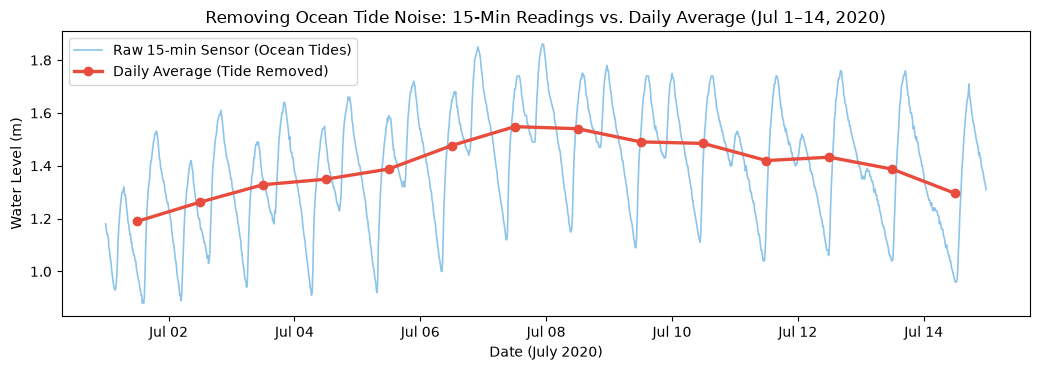

In [2]:
# ==============================================================================
# CLEAN BASSAC_01 (15-MINUTE SENSOR -> DAILY AVERAGE)
# ==============================================================================

# ==============================================================================
# CONVERT TEXT DATES TO TIMESTAMPS & REMOVE DUPLICATES
# ==============================================================================
bassac_raw['dt'] = pd.to_datetime(bassac_raw['Date'], format='%d/%m/%Y %H:%M', errors='coerce')
bassac_raw['WL'] = pd.to_numeric(bassac_raw['WL'], errors='coerce')

clean_15min = (
    bassac_raw
    .dropna(subset=['dt', 'WL'])
    .sort_values('dt')
    .drop_duplicates(subset=['dt'])
)

# ==============================================================================
# AVERAGE 96 READINGS PER DAY INTO 1 DAILY VALUE (REMOVES OCEAN TIDE SWINGS)
# ==============================================================================
sensor_by_time = clean_15min.set_index('dt')['WL']
daily_avg_wl = sensor_by_time.resample('D').mean()
readings_per_day = sensor_by_time.resample('D').count()

bassac_daily = pd.DataFrame({
    'date': daily_avg_wl.index.strftime('%Y-%m-%d'),
    'WL': daily_avg_wl.values,
    'n_readings': readings_per_day.values,
})

# Hide partial days (< 90 of 96 readings) so missing morning/evening tides do not skew the average
bassac_daily.loc[bassac_daily['n_readings'] < 90, 'WL'] = np.nan

# ==============================================================================
# FILL SENSOR OUTAGE (DEC 2021 - MAR 2022) USING PREVIOUS DRY SEASON SHAPE
# ==============================================================================
daily_series = bassac_daily.assign(dt=pd.to_datetime(bassac_daily['date'])).set_index('dt')['WL']
outage_dates = daily_series.loc['2021-12-01':'2022-03-18'].index

# Copy the same dates from 1 year earlier (2020-2021), then smoothly align start & end heights
last_year_shape = daily_series.loc[outage_dates - pd.DateOffset(years=1)].values
start_diff = daily_series.loc['2021-11-30'] - daily_series.loc[pd.Timestamp('2021-11-30') - pd.DateOffset(years=1)]
end_diff = daily_series.loc['2022-03-19'] - daily_series.loc[pd.Timestamp('2022-03-19') - pd.DateOffset(years=1)]
smooth_offset = np.linspace(start_diff, end_diff, len(outage_dates))

daily_series.loc[outage_dates] = np.round(last_year_shape + smooth_offset, 4)
bassac_daily['WL'] = daily_series.values

# Save cleaned daily table
bassac_daily.to_csv(PROCESSED_DIR / 'bassac_daily.csv', index=False)
print('bassac_daily:', bassac_daily.shape, '| Valid WL:', bassac_daily['WL'].notna().sum(), '| Missing:', bassac_daily['WL'].isna().sum())

# ==============================================================================
# PLOT 14-DAY ZOOM: RAW 15-MIN TIDAL WAVES VS. CLEANED DAILY AVERAGE
# ==============================================================================
import matplotlib.dates as mdates

sample_14days_15m = clean_15min[(clean_15min['dt'] >= '2020-07-01') & (clean_15min['dt'] < '2020-07-15')]
sample_14days_avg = bassac_daily[(bassac_daily['date'] >= '2020-07-01') & (bassac_daily['date'] <= '2020-07-14')].copy()
sample_14days_avg['dt'] = pd.to_datetime(sample_14days_avg['date']) + pd.Timedelta(hours=12)

fig, ax = plt.subplots(figsize=(10.5, 3.8))
ax.plot(sample_14days_15m['dt'], sample_14days_15m['WL'], label='Raw 15-min Sensor (Ocean Tides)', color='#5dade2', alpha=0.7, linewidth=1.2)
ax.plot(sample_14days_avg['dt'], sample_14days_avg['WL'], 'o-', label='Daily Average (Tide Removed)', color='#e74c3c', linewidth=2.4, markersize=6)
ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.set_ylabel('Water Level (m)')
ax.set_xlabel('Date (July 2020)')
ax.set_title('Removing Ocean Tide Noise: 15-Min Readings vs. Daily Average (Jul 1–14, 2020)')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()


kohkhel_daily  : (1511, 2)
glofas_daily   : (2353, 2)
nasa_rain_daily: (2363, 2)


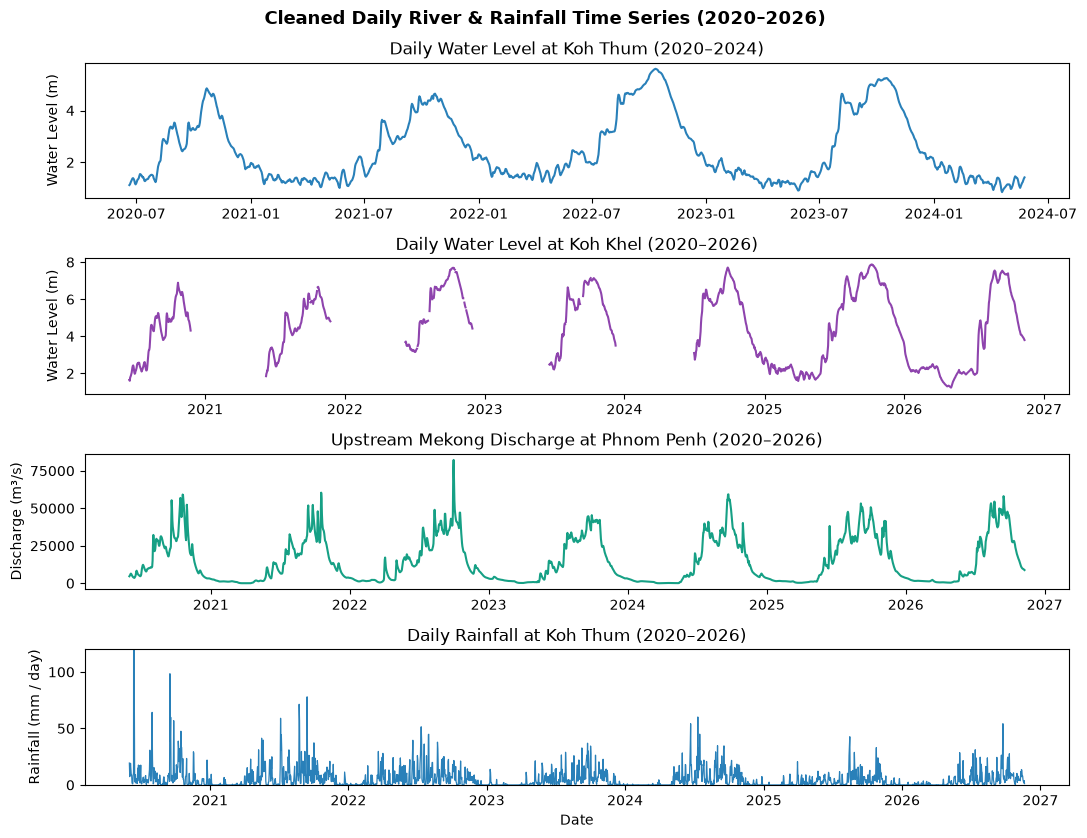

In [3]:
# ==============================================================================
# CLEAN KOH KHEL, PHNOM PENH DISCHARGE, AND DAILY RAINFALL
# ==============================================================================

# ==============================================================================
# CLEAN KOH KHEL WATER LEVEL (KEEP BASSAC STATION ONLY & FILL 1-DAY GAPS)
# ==============================================================================
kohkhel_base = pd.DataFrame({
    'date': pd.to_datetime(dhrw_raw['date'], errors='coerce'),
    'WL_raw': pd.to_numeric(dhrw_raw['Koh_Khel'], errors='coerce'),
}).dropna().sort_values('date').drop_duplicates(subset=['date']).reset_index(drop=True)

# Keep 2020-2023 flood-only rows as-is; fill any 1-day missing gaps from Jul 2024 onward
before_jul2024 = kohkhel_base[kohkhel_base['date'] < '2024-07-01'].copy()
from_jul2024 = kohkhel_base[kohkhel_base['date'] >= '2024-07-01'].set_index('date')['WL_raw'].asfreq('D')
from_jul2024 = from_jul2024.interpolate(method='linear', limit=1).round(2).reset_index()

kohkhel_daily = pd.concat([before_jul2024, from_jul2024], ignore_index=True).sort_values('date').reset_index(drop=True)
kohkhel_daily['date'] = kohkhel_daily['date'].dt.strftime('%Y-%m-%d')

# ==============================================================================
# CLEAN UPSTREAM MEKONG DISCHARGE AT PHNOM PENH (2020 - 2026)
# ==============================================================================
glofas_daily = pd.DataFrame({
    'date': pd.to_datetime(glofas_raw['date'], errors='coerce'),
    'upstream_discharge': pd.to_numeric(glofas_raw['Q'], errors='coerce'),
}).dropna().sort_values('date').drop_duplicates(subset=['date']).reset_index(drop=True)

# Keep 2020-06-01 onward to match the Bassac River study period
glofas_daily = glofas_daily[glofas_daily['date'] >= '2020-06-01'].reset_index(drop=True)
glofas_daily['date'] = glofas_daily['date'].dt.strftime('%Y-%m-%d')

# ==============================================================================
# CLEAN DAILY RAINFALL AT KOH THUM (BUILD DATE & REMOVE -999 MISSING VALUES)
# ==============================================================================
nasa_raw['date'] = pd.to_datetime(dict(year=nasa_raw['YEAR'], month=nasa_raw['MO'], day=nasa_raw['DY']), errors='coerce')
nasa_raw['rain_mm'] = pd.to_numeric(nasa_raw['PRECTOTCORR'], errors='coerce')
nasa_raw.loc[nasa_raw['rain_mm'] < 0, 'rain_mm'] = np.nan

nasa_rain_daily = nasa_raw[['date', 'rain_mm']].dropna().sort_values('date').drop_duplicates(subset=['date']).reset_index(drop=True)
nasa_rain_daily['date'] = nasa_rain_daily['date'].dt.strftime('%Y-%m-%d')

# ==============================================================================
# SAVE CLEANED DAILY TABLES
# ==============================================================================
kohkhel_daily.to_csv(PROCESSED_DIR / 'kohkhel_daily.csv', index=False)
glofas_daily.to_csv(PROCESSED_DIR / 'glofas_daily.csv', index=False)
nasa_rain_daily.to_csv(PROCESSED_DIR / 'nasa_rain_daily.csv', index=False)

print('kohkhel_daily  :', kohkhel_daily.shape)
print('glofas_daily   :', glofas_daily.shape)
print('nasa_rain_daily:', nasa_rain_daily.shape)

# ==============================================================================
# PLOT ALL 4 CLEANED DAILY SERIES (2020 - 2026)
# ==============================================================================
fig, axes = plt.subplots(4, 1, figsize=(11, 8.5))

# ==============================================================================
# CHART 1: DAILY WATER LEVEL AT KOH THUM (2020 - 2024)
# ==============================================================================
axes[0].plot(pd.to_datetime(bassac_daily['date']), bassac_daily['WL'], color='#2980b9')
axes[0].set_title('Daily Water Level at Koh Thum (2020–2024)')
axes[0].set_ylabel('Water Level (m)')

# ==============================================================================
# CHART 2: DAILY WATER LEVEL AT KOH KHEL (2020 - 2026)
# ==============================================================================
kohkhel_by_day = kohkhel_daily.assign(dt=pd.to_datetime(kohkhel_daily['date'])).set_index('dt')['WL_raw'].asfreq('D')
axes[1].plot(kohkhel_by_day.index, kohkhel_by_day.values, color='#8e44ad')
axes[1].set_title('Daily Water Level at Koh Khel (2020–2026)')
axes[1].set_ylabel('Water Level (m)')

# ==============================================================================
# CHART 3: UPSTREAM MEKONG DISCHARGE AT PHNOM PENH (2020 - 2026)
# ==============================================================================
axes[2].plot(pd.to_datetime(glofas_daily['date']), glofas_daily['upstream_discharge'], color='#16a085')
axes[2].set_title('Upstream Mekong Discharge at Phnom Penh (2020–2026)')
axes[2].set_ylabel('Discharge (m³/s)')

# ==============================================================================
# CHART 4: DAILY RAINFALL AT KOH THUM IN MM (2020 - 2026)
# ==============================================================================
axes[3].plot(pd.to_datetime(nasa_rain_daily['date']), nasa_rain_daily['rain_mm'], color='#2980b9', linewidth=0.9)
axes[3].set_ylim(0, 120)
axes[3].set_ylabel('Rainfall (mm / day)')
axes[3].set_xlabel('Date')
axes[3].set_title('Daily Rainfall at Koh Thum (2020–2026)')

fig.suptitle('Cleaned Daily River & Rainfall Time Series (2020–2026)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()
